# neural-processor 01 · Signals up close: ratios, price, short interest, transforms

`00_signals.ipynb` surveyed the whole catalogue over a universe. This notebook looks at how
single signals are built and checked: the ratio library and its rules, a price signal verified
by hand against daily bars, short-interest signals and their publication lag, growth signals
across a split, the per-date transforms, and how a company is followed across a change of
security. It uses neural-processor with the packages it depends on (vinculum for fundamentals and
universes, Massive for bars).

1. the ratio library
2. a price signal, verified by hand
3. short-interest signals and the publication lag
4. growth signals across a split
5. transforms: winsorize, neutralize, standardize
6. lineage: one company, two securities

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from neural_processor import SIGNALS, Processor, catalogue, security_links, transform
from subspace_probe import style, timed
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(80)
v, massive = Vinculum(), Store()
p = Processor(vinculum=v, store=massive)
RATIO_NAMES = [n for n, s in SIGNALS.items() if s.group in ("value", "profitability", "quality", "leverage")]
print(len(RATIO_NAMES), "ratio signals")

31 ratio signals


## 1 · The ratio library

`SIGNALS` holds each ratio's formula, the EDGAR items it needs and the direction the literature
expects (+1: higher has gone with higher returns). `Processor.panel()` loads only the items the
requested signals need. Rules used throughout:

- A ratio over market cap or enterprise value needs a USD reporter (no FX conversion).
  Within-company ratios (margins, returns, leverage) use one filing's currency and work for
  every company.
- A denominator must be positive: ROE of a company with negative equity, or a margin on zero
  revenue, is missing rather than a misleading sign flip.
- Enterprise value is approximated as market cap + long-term debt + short-term borrowings −
  cash (no leases, preferred stock or minority interest among the items).
- Missing `dividends_paid`, `buybacks` and `capex` stay missing (zero would be right for a
  company that returns no cash, wrong for one filing under a tag outside the catalogue), except
  in `shareholder_yield`, which needs one of the two.
- Returns use TTM flows over the latest balance sheet, not an average of two.

In [2]:
catalogue().filter(pl.col("name").is_in(RATIO_NAMES)).select("name", "group", "formula", "direction", "items", "needs_usd", "note")

name,group,formula,direction,items,needs_usd,note
str,str,str,i64,list[str],bool,str
"""earnings_yield""","""value""","""net income / market cap (inverse P/E)""",1,"[""net_income""]",true,""""""
"""book_to_market""","""value""","""equity / market cap""",1,"[""equity""]",true,""""""
"""sales_to_price""","""value""","""revenue / market cap""",1,"[""revenue""]",true,""""""
"""cash_flow_yield""","""value""","""operating cash flow / market cap""",1,"[""operating_cash_flow""]",true,""""""
"""fcf_yield""","""value""","""(operating cash flow - capex) / market cap""",1,"[""operating_cash_flow"", ""capex""]",true,""""""
"""dividend_yield""","""value""","""dividends paid / market cap""",1,"[""dividends_paid""]",true,""""""
"""shareholder_yield""","""value""","""(dividends + buybacks) / market cap; a missing one counts as 0""",1,"[""dividends_paid"", ""buybacks""]",true,""""""
"""ebit_to_ev""","""value""","""operating income / EV""",1,"[""operating_income"", ""long_term_debt"", … ""cash""]",true,""""""
"""ebitda_to_ev""","""value""","""(operating income + D&A) / EV""",1,"[""operating_income"", ""depreciation_amortization"", … ""cash""]",true,""""""


Well-known companies on the latest month end. Reading down a column is a health check: Apple's
gross margin near half of revenue, Nvidia's operating margin above 60%, Coca-Cola paying out most
of its earnings, JPMorgan without gross or operating margin (banks have no such lines), gaps
where an item is filed under a tag outside the catalogue.

In [3]:
with timed("ratio panel, top 1,000, since mid-2026"):
    r = p.panel(RATIO_NAMES, start="2026-06-01", top=1000)
last = r["date"].max()
names = ["AAPL", "MSFT", "NVDA", "AMZN", "TSLA", "JPM", "KO", "WMT", "CVX", "PFE"]
snap = r.filter((pl.col("date") == last) & pl.col("ticker").is_in(names))
print(f"as known on {last}")
snap.to_pandas().set_index("ticker").loc[[n for n in names if n in snap["ticker"]], RATIO_NAMES].T.round(3)

ratio panel, top 1,000, since mid-2026: 0.99 s
as known on 2026-11-03


ticker,AAPL,MSFT,NVDA,AMZN,TSLA,JPM,KO,WMT,CVX,PFE
earnings_yield,0.027,0.037,0.039,0.050,0.002,0.072,0.036,0.022,0.046,0.025
book_to_market,0.022,0.122,0.046,0.226,0.057,0.417,0.092,0.099,0.427,0.498
sales_to_price,0.096,0.090,0.061,0.294,0.066,0.222,0.125,0.743,0.484,0.373
cash_flow_yield,0.030,0.051,0.027,0.062,0.012,-0.181,0.040,0.043,0.102,0.078
fcf_yield,0.028,0.015,0.025,-0.017,0.002,NaN,0.035,0.014,0.061,0.064
dividend_yield,0.003,0.007,0.001,NaN,NaN,0.019,0.028,0.008,0.031,0.057
shareholder_yield,0.020,0.012,0.012,NaN,NaN,0.055,0.030,0.015,0.056,0.057
ebit_to_ev,0.032,0.042,0.040,0.037,0.002,NaN,0.039,0.031,NaN,NaN
ebitda_to_ev,0.034,NaN,0.040,0.065,NaN,NaN,0.041,0.046,NaN,NaN
sales_to_ev,0.095,0.089,0.061,0.281,0.066,0.302,0.129,0.717,0.494,0.276


## 2 · A price signal, verified by hand

`momentum_12_1` is the total return from 12 months to 1 month before the date, from bars adjusted
for splits and dividends, using only closes up to that day. Rebuilding it from `Store.bars` for
Apple on one month end gives the same number.

daily price signals for AAPL and GME, 2024-2025: 0.68 s


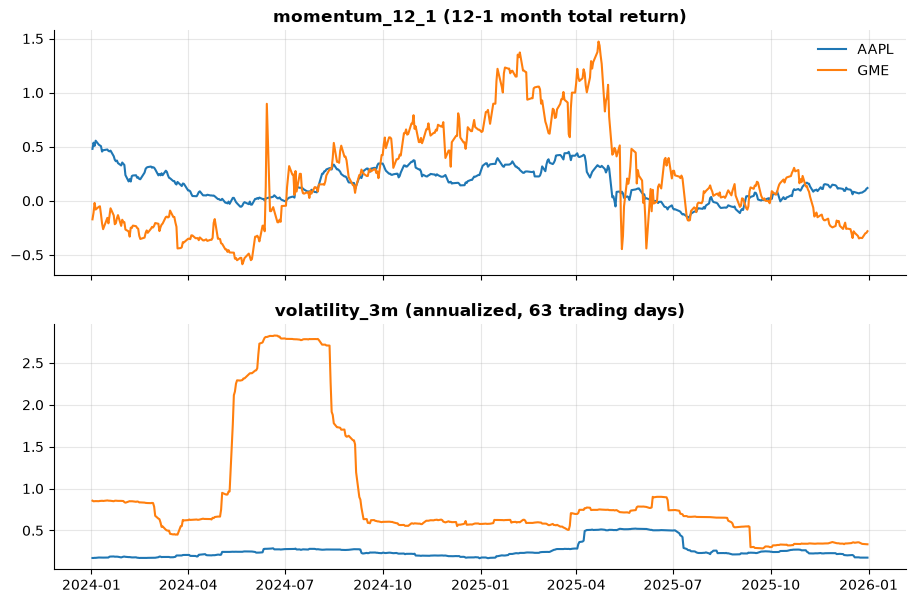

In [4]:
with timed("daily price signals for AAPL and GME, 2024-2025"):
    d = p.panel(["momentum_12_1", "reversal_1m", "high_52w", "volatility_3m", "beta_12m", "turnover", "illiquidity"],
                start="2024-01-01", end="2025-12-31", tickers=["AAPL", "GME"], by="security", freq="1d")
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for (t,), g in d.group_by("ticker", maintain_order=True):
    axes[0].plot(g["date"], g["momentum_12_1"], label=t)
    axes[1].plot(g["date"], g["volatility_3m"], label=t)
axes[0].set_title("momentum_12_1 (12-1 month total return)")
axes[1].set_title("volatility_3m (annualized, 63 trading days)")
axes[0].legend()
plt.show()

In [5]:
day = pl.date(2025, 6, 30)
bars = massive.bars("AAPL", start="2024-05-01", end="2025-06-30", adjust="all").select("date", "close").sort("date")


def close_on_or_before(when):
    return bars.filter(pl.col("date") <= when)["close"][-1]


one_month = bars.select(day.dt.offset_by("-1mo")).item()
twelve = bars.select(day.dt.offset_by("-12mo")).item()
by_hand = close_on_or_before(one_month) / close_on_or_before(twelve) - 1
from_panel = d.filter((pl.col("ticker") == "AAPL") & (pl.col("date") == bars.select(day).item()))["momentum_12_1"][0]
print(f"AAPL momentum_12_1 on 2025-06-30: by hand {by_hand:.4f}, from the panel {from_panel:.4f}")

AAPL momentum_12_1 on 2025-06-30: by hand -0.0419, from the panel -0.0419


## 3 · Short-interest signals and the publication lag

Short signals take FINRA's latest report **published** on or before the date (within 35 days),
never the latest settlement. `si_pct_float` is short interest as a share of the float-adjusted
market cap; `days_to_cover` is FINRA's own. GameStop and AMC through 2021:

short signals, monthly: 0.18 s


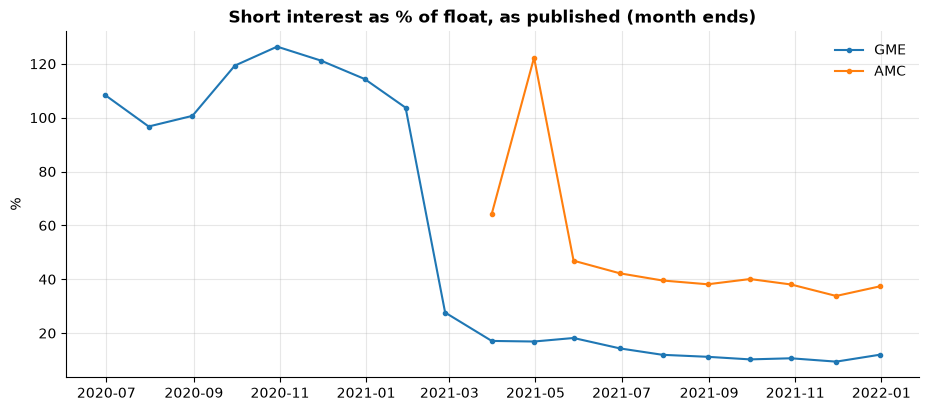

date,si_pct_float,si_pct_market_cap,days_to_cover,si_change
date,f64,f64,f64,f64
2020-06-30,1.084533,0.92637,11.53,0.064844
2020-07-31,0.967191,0.826141,25.82,-0.019422
2020-08-31,1.006754,0.859934,15.5,0.021345
2020-09-30,1.193159,1.019154,6.1,0.147747
2020-10-30,1.26372,1.079425,3.55,0.024896
2020-11-30,1.211922,1.035181,14.05,0.009696
2020-12-31,1.143545,0.976775,6.89,0.002133
2021-01-29,1.037051,0.885813,2.1,-0.132219


In [6]:
with timed("short signals, monthly"):
    s = p.panel("short", start="2020-06-01", end="2021-12-31", tickers=["GME", "AMC"], by="security")
fig, ax = plt.subplots()
for (t,), g in s.group_by("ticker", maintain_order=True):
    ax.plot(g["date"], g["si_pct_float"] * 100, marker="o", ms=3, label=t)
ax.set_title("Short interest as % of float, as published (month ends)")
ax.set_ylabel("%")
ax.legend()
plt.show()
s.filter(pl.col("ticker") == "GME").select("date", "si_pct_float", "si_pct_market_cap", "days_to_cover", "si_change").head(8)

## 4 · Growth signals across a split

Growth signals compare each month's value with the row twelve month ends earlier, both point in
time (never restated). Per-share and per-share-count growth are put in the same share units with
the security's split factor, so Nvidia's 10-for-1 split of June 2024 leaves `eps_growth` and
`share_issuance` undisturbed.

In [7]:
g = p.panel("growth", start="2023-06-01", end="2025-06-30", tickers="NVDA", by="security")
g.select("date", "revenue_growth", "earnings_growth", "eps_growth", "asset_growth", "share_issuance").with_columns(pl.col(pl.Float64).round(3))

date,revenue_growth,earnings_growth,eps_growth,asset_growth,share_issuance
date,f64,f64,f64,f64,f64
2023-06-30,-0.124,-0.103,-0.485,-0.017,-0.012
2023-07-31,-0.124,-0.103,-0.485,-0.017,-0.012
2023-08-31,0.106,0.019,0.11,0.096,-0.012
2023-09-29,0.099,0.059,0.357,0.14,-0.008
2023-10-31,0.099,0.059,0.357,0.14,-0.008
2023-11-30,0.571,0.319,2.226,0.337,0.004
2023-12-29,0.571,0.319,2.226,0.337,0.004
2024-01-31,0.571,0.319,2.226,0.337,0.004
2024-02-29,1.259,0.617,5.856,0.596,0.012


## 5 · Transforms: winsorize, neutralize, standardize

Everything cross-sectional happens per date and never looks at other dates. `transform` clips
the tails, removes sector means and the size slope, then z-scores or ranks. Earnings yield on the
latest month end, before and after:

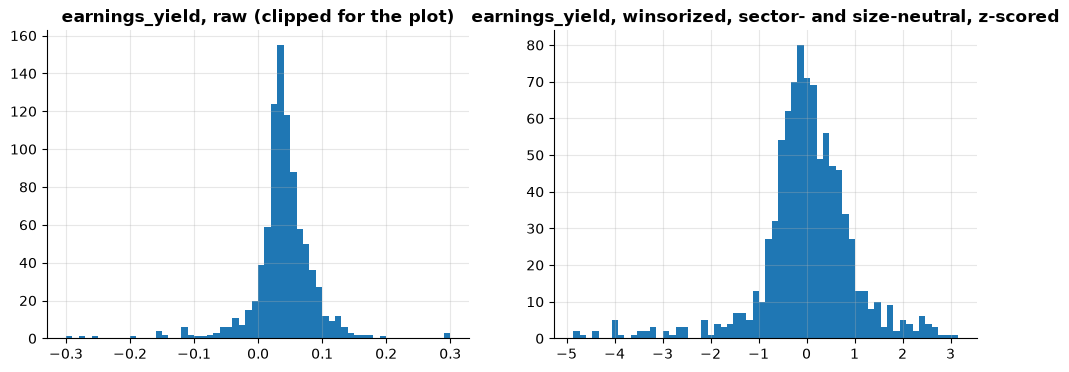

signal,corr_with_log_size_raw,corr_with_log_size_after
str,f64,f64
"""earnings_yield""",0.03,0.0
"""book_to_market""",-0.213,-0.0
"""roe""",0.04,0.0


In [8]:
cols = ["earnings_yield", "book_to_market", "roe"]
raw = r.filter(pl.col("date") == last)
z = transform(raw, cols, method="zscore", winsor=0.01, neutralize_on=["sector", "size"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw["earnings_yield"].drop_nulls().clip(-0.3, 0.3), bins=60)
axes[0].set_title("earnings_yield, raw (clipped for the plot)")
axes[1].hist(z["earnings_yield"].drop_nulls(), bins=60)
axes[1].set_title("earnings_yield, winsorized, sector- and size-neutral, z-scored")
plt.show()
size = pl.col("issuer_market_cap").log()
pl.DataFrame({"signal": cols,
              "corr_with_log_size_raw": [raw.select(pl.corr(c, size)).item() for c in cols],
              "corr_with_log_size_after": [z.select(pl.corr(c, size)).item() for c in cols]}).with_columns(pl.col(pl.Float64).round(3))

## 6 · Lineage: one company, two securities

When a company moves to a new security (a holding-company reorganization, a re-domicile),
vinculum records the handoff and neural-processor treats the predecessor's rows before the link
as the successor's, so look-back signals do not restart from nothing. ExxonMobil's July 2026
move: with both securities in the panel, the new security's first month already has a
twelve-month momentum, a three-month volatility and revenue growth against a year earlier, all
taken from the old security's history; the old security's own rows end at the link.

In [9]:
links = security_links(v.successors())
xom = links.join(v.successors().filter(pl.col("ticker") == "XOM").select("security_id"), on="security_id").row(0, named=True)
print(xom)
both = [xom["predecessor_id"], xom["security_id"]]                 # the old security and the new one
m = p.panel(["momentum_12_1", "volatility_3m", "revenue_growth"], start="2026-03-01", tickers=both, by="security")
# The new security's rows: their look-back windows reach into the old security's history.
m.filter(pl.col("security_id") == xom["security_id"]).select(
    "date", "security_id", "ticker", "momentum_12_1", "volatility_3m", "revenue_growth").with_columns(pl.col(pl.Float64).round(3))

{'predecessor_id': 'BBG000GZQ728', 'security_id': 'BBG023CY9MM1', 'link_date': datetime.date(2026, 7, 2)}


date,security_id,ticker,momentum_12_1,volatility_3m,revenue_growth
date,str,str,f64,f64,f64
2026-07-31,"""BBG023CY9MM1""","""XOM""",0.264,0.289,-0.044
2026-08-31,"""BBG023CY9MM1""","""XOM""",0.39,0.265,-0.011
2026-09-30,"""BBG023CY9MM1""","""XOM""",0.43,0.258,-0.011
2026-10-30,"""BBG023CY9MM1""","""XOM""",0.46,0.243,-0.011
2026-11-03,"""BBG023CY9MM1""","""XOM""",0.484,0.257,0.003


## Takeaways
- Every signal is defined once in `SIGNALS` with its items and direction; a new one is one more
  expression over the same point-in-time panel.
- Price signals use bars up to the day's close; short signals use reports published by that
  day; growth signals compare with the row a year earlier, never restated.
- Transforms are per date; sector and size neutralization removes most of the size tilt in
  valuation ratios.
- Securities are followed across handoffs, so a reorganization does not reset momentum or
  growth.